In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

pd.set_option("display.max_columns", None)

#### Objective

Interpret the credit risk model by:

- Understanding why borrowers are risky
- Identifying major risk drivers
- Explaining model decisions
- Comparing borrowers
- Simulating what-if scenarios
- Preparing explanations for the GenAI layer

Outputs:
- Feature importance
- Risk driver analysis
- Borrower explanations
- Borrower comparison
- Scenario analysis

In [3]:
model = joblib.load("../models/logistic_model.pkl")

scorecard = joblib.load("../models/scorecard.pkl")

In [4]:
X_train = pd.read_csv(
    "../outputs/X_train.csv",
    index_col=0
)

X_test = pd.read_csv(
    "../outputs/X_test.csv",
    index_col=0
)

y_test = pd.read_csv(
    "../outputs/y_test.csv",
    index_col=0
)

test_score = pd.read_csv(
    "../outputs/customer_scores.csv",
    index_col=0
)

In [5]:
print(X_train.shape)
print(X_test.shape)

test_score.head()

(204015, 13)
(87436, 13)


,score,PD,Actual,RiskBand
103986,624.0,0.210437,0,Medium Risk
30381,583.0,0.521656,1,Medium Risk
25653,630.0,0.177745,0,Medium Risk
30279,587.0,0.487582,0,Medium Risk
145660,641.0,0.127592,0,Medium Risk


In [6]:
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_[0]
})

coef_df = coef_df.sort_values(
    by="Coefficient",
    ascending=False
)

coef_df

,Feature,Coefficient
10,NumBorrowers_woe,1.038191
0,CreditScore_woe,0.988625
1,MonthsInRepayment_woe,0.978191
11,OrigInterestRate_woe,0.828695
3,MSA_woe,0.542533
9,DTI_woe,0.332538
6,SellerName_woe,0.317688
2,ServicerName_woe,0.213083
7,LTV_woe,0.104032
8,OCLTV_woe,0.099625


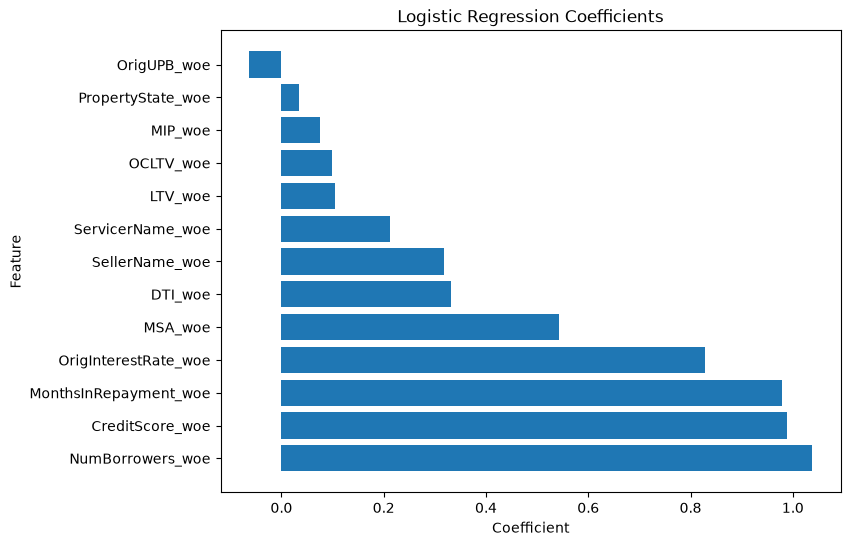

In [7]:
plt.figure(figsize=(8,6))

plt.barh(
    coef_df["Feature"],
    coef_df["Coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Logistic Regression Coefficients")

plt.show()

In [8]:
coef_df["Importance"] = abs(coef_df["Coefficient"])

coef_df.sort_values(
    "Importance",
    ascending=False
)

,Feature,Coefficient,Importance
10,NumBorrowers_woe,1.038191,1.038191
0,CreditScore_woe,0.988625,0.988625
1,MonthsInRepayment_woe,0.978191,0.978191
11,OrigInterestRate_woe,0.828695,0.828695
3,MSA_woe,0.542533,0.542533
9,DTI_woe,0.332538,0.332538
6,SellerName_woe,0.317688,0.317688
2,ServicerName_woe,0.213083,0.213083
7,LTV_woe,0.104032,0.104032
8,OCLTV_woe,0.099625,0.099625


In [9]:
test_score["BorrowerID"] = test_score.index

test_score.head()

,score,PD,Actual,RiskBand,BorrowerID
103986,624.0,0.210437,0,Medium Risk,103986
30381,583.0,0.521656,1,Medium Risk,30381
25653,630.0,0.177745,0,Medium Risk,25653
30279,587.0,0.487582,0,Medium Risk,30279
145660,641.0,0.127592,0,Medium Risk,145660


In [10]:
test_score.sort_values(
    "PD",
    ascending=False
).head(10)

,score,PD,Actual,RiskBand,BorrowerID
15696,524.0,0.890330,1,High Risk,15696
9827,526.0,0.889965,1,High Risk,9827
18243,527.0,0.880315,1,High Risk,18243
19494,529.0,0.877596,1,High Risk,19494
12993,531.0,0.872678,1,High Risk,12993
11041,531.0,0.869441,0,High Risk,11041
47433,533.0,0.859829,1,High Risk,47433
10769,533.0,0.858791,1,High Risk,10769
10488,534.0,0.858024,1,High Risk,10488
28013,536.0,0.852880,1,High Risk,28013
